# 实验报告02：NumPy、SciPy、Matplotlib与pandas数据处理

## 1. 身份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = "20244080306"

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python_env
[学号] 20244080306
[机器指纹] 1a31167f0910eb30
[RUN_ID] 20244080306-1a31167f0910eb30


## 2. 实验1：NumPy数组、数据类型与索引

### 2.1 实验1 操作任务1：创建数组与属性

分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和 ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。

In [2]:
# 创建不同类型的 ndarray
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])

for name, arr in [("整数", arr_int), ("浮点", arr_float), ("布尔", arr_bool)]:
    print(f"{name}数组: {arr}, dtype: {arr.dtype}, shape: {arr.shape}, ndim: {arr.ndim}")

整数数组: [1 2 3], dtype: int64, shape: (3,), ndim: 1
浮点数组: [1.1 2.2 3.3], dtype: float64, shape: (3,), ndim: 1
布尔数组: [ True False  True], dtype: bool, shape: (3,), ndim: 1


**关键结果解释：**
- 从输出结果看，NumPy 数组强制要求所有元素的类型一致（同质化），因此产生了 `int64`、`float64`、`bool` 这样的专属 `dtype`。
- **与 Python 列表的差别：** Python 列表可以混合存放不同类型的数据，而 NumPy 数组为了保证底层 C 语言连续内存块的极速计算性能，必须保持数据类型统一。如果强行塞入混合类型，NumPy 会自动将其向上转换为兼容的类型（如字符串）。

### 2.2 实验1 操作任务2：数组变形

用 np.arange(12) 创建一维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的数组。

In [3]:
arr_1d = np.arange(12)
arr_3x4 = arr_1d.reshape(3, 4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)

print("(3, 4) 数组:\n", arr_3x4)
print("(2, 3, 2) 数组:\n", arr_2x3x2)

(3, 4) 数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 3, 2) 数组:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**关键结果解释：**
- 输出结果显示，原本的一维数组被成功重组为二维表格（3行4列）和三维张量（2块3行2列），且元素按行主序填充。
- **满足条件：** 改变形状时，**新形状各维度的乘积必须等于原数组的元素总数**。原数组有 12 个元素，`3*4=12`，`2*3*2=12`，因此合法；若不相等（如 reshape(3,5)）则会报错。

### 2.3 实验1 操作任务3：索引操作

对形状为 (3, 4) 的数组取第 2 行、第 1 至第 3 列、大于 6 的元素。

In [4]:
# 第2行 (索引为1)
row_2 = arr_3x4[1, :]
# 第1至第3列 (索引0到2)
cols_1_to_3 = arr_3x4[:, 0:3]
# 大于6的元素
greater_than_6 = arr_3x4[arr_3x4 > 6]

print("第2行:", row_2, "形状:", row_2.shape)
print("第1至第3列:\n", cols_1_to_3, "形状:", cols_1_to_3.shape)
print("大于6的元素:", greater_than_6, "形状:", greater_than_6.shape)

第2行: [4 5 6 7] 形状: (4,)
第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状: (3, 3)
大于6的元素: [ 7  8  9 10 11] 形状: (5,)


**关键结果解释：**
- 取单行 `[1, :]` 后，结果形状从二维降为一维 `(4,)`。
- 取多列切片 `[:, 0:3]` 后，保留了二维结构 `(3, 3)`。
- 布尔索引 `[arr > 6]` 筛选后，符合条件的元素被提取并**展平为一维**数组 `[ 7 8 9 10 11]`，形状为 `(5,)`。

### 2.4 实验1 操作任务4：布尔索引

使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。

In [5]:
arr_10 = np.arange(10)

# 小于2或大于7
cond_or = (arr_10 < 2) | (arr_10 > 7)
print("小于2或大于7:", arr_10[cond_or])

# 大于3且小于7
cond_and = (arr_10 > 3) & (arr_10 < 7)
print("大于3且小于7:", arr_10[cond_and])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]


**关键结果解释：**
- 运行结果成功提取了 `[0 1 8 9]` 和 `[4 5 6]`。
- 在使用 NumPy 进行多条件筛选时，必须用 `|` 代表逻辑或，用 `&` 代表逻辑与，并且**每个条件必须用圆括号包裹**。如果不加括号，由于 Python 运算符优先级，会导致不可预期的按位运算错误。

### 2.5 实验1 操作任务5：矩阵乘法与逐元素乘法

构造两个形状为 (2, 2) 的数组，对比 *、np.multiply() 与 @、np.matmul() 的结果，说明区别。

In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B (逐元素乘法):\n", A * B)
print("np.multiply(A, B) (同上):\n", np.multiply(A, B))
print("A @ B (矩阵乘法):\n", A @ B)
print("np.matmul(A, B) (同上):\n", np.matmul(A, B))

A * B (逐元素乘法):
 [[ 5 12]
 [21 32]]
np.multiply(A, B) (同上):
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul(A, B) (同上):
 [[19 22]
 [43 50]]


**关键结果解释：**
- `*` 和 `np.multiply()` 得到的结果相同，是对应位置元素直接相乘（例如 `1*5=5`, `2*6=12`），称为**逐元素乘法（Hadamard积）**。
- `@` 和 `np.matmul()` 得到的是**线性代数矩阵乘法**，计算结果的行列元素由左矩阵的行和右矩阵的列进行点积求和得出（例如左上角元素 `1*5 + 2*7 = 19`）。

## 3. 实验2：随机抽样、统计与缺失值

### 3.1 实验2 操作任务1：模拟成绩与统计

生成 1,000 个均值为 70、标准差为 10 的模拟成绩，用 np.clip 限制在 0~100。输出样本数、最小值、最大值、均值、标准差和极差。

In [7]:
np.random.seed(42) # 固定种子，保证结果可复现
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100) # 截断异常值

print("样本数:", len(scores))
print("最小值:", np.min(scores))
print("最大值:", np.max(scores))
print("均值:", np.mean(scores))
print("标准差:", np.std(scores))
print("极差:", np.max(scores) - np.min(scores))

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


**关键结果解释：**
- 样本数输出为 1000。输出的最大值和最小值都在 0~100 范围内，证明 `np.clip` 截断生效。
- 样本均值约为 70 左右，标准差约为 10 左右，极差等于最大值减去最小值，符合正态分布的统计学特征。 
- 固定随机种子 `42` 保证了结果的可复现性。

### 3.2 实验2 操作任务2：抽样对比

从 np.arange(1, 11) 中不放回地抽取 5 个整数，比较均匀抽样与按大小加权抽样的写法。

In [8]:
pop = np.arange(1, 11)

# 均匀抽样
uniform_sample = np.random.choice(pop, size=5, replace=False)

# 加权抽样 (按整数大小比例)
weights = pop / np.sum(pop) 
weighted_sample = np.random.choice(pop, size=5, replace=False, p=weights)

print("均匀抽样:", uniform_sample)
print("加权抽样:", weighted_sample)

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]


**关键结果解释：**
- 均采用 `replace=False` 实现不放回抽取。
- 均匀抽样中，数字 1 到 10 每个被抽中的概率均为 10%；加权抽样中，利用 `p` 参数传入概率列表，因为数字越大权重越高，所以抽出的结果明显偏向较大的整数。

### 3.3 实验2 操作任务3：随机排列与原地打乱

演示随机排列后保留原数组和原地打乱数组的区别。

In [9]:
arr_orig = np.arange(5)
print("原数组:", arr_orig)

# 随机排列 (返回新数组)
arr_permuted = np.random.permutation(arr_orig)
print("permutation 后原数组:", arr_orig)
print("permutation 新数组:", arr_permuted)

# 原地打乱
arr_shuffled = arr_orig.copy()
np.random.shuffle(arr_shuffled)
print("shuffle 后原数组 (被修改):", arr_shuffled)

原数组: [0 1 2 3 4]
permutation 后原数组: [0 1 2 3 4]
permutation 新数组: [4 0 2 1 3]
shuffle 后原数组 (被修改): [0 4 1 3 2]


**关键结果解释：**
- 打印结果显示，`permutation` 操作后，原数组 `arr_orig` 的元素顺序并未改变，说明它返回的是一个打乱后的**新数组**。
- `shuffle` 操作后，传入的数组元素顺序发生了变化，说明它是在原数组内存上**原地打乱**，没有返回新数组。

### 3.4 实验2 操作任务4：处理缺失值

将模拟成绩的第 10、20、30 个值设为 np.nan。比较普通均值和忽略缺失值后的均值，统计缺失值个数。

In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan # 索引从0开始，所以第10个是索引9

print("普通均值 (含nan):", np.mean(scores_nan))
print("忽略缺失值均值 (nanmean):", np.nanmean(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值 (含nan): nan
忽略缺失值均值 (nanmean): 70.19620743160239
缺失值个数: 3


**关键结果解释：**
- 普通均值输出了 `nan`，这证明 `np.nan` 具有**传染性**。只要数据中存在一个 `nan`，使用 `np.mean()` 等普通统计函数计算出的结果永远为 `nan`。
- `np.nanmean()` 输出了正常的浮点数，说明它能够自动忽略缺失值，只对有效数据进行计算。缺失值个数统计输出为 3，与我们的设定完全一致。

### 3.5 实验2 操作任务5：整理为表格变量

将含缺失值的模拟成绩及序号整理成内存中的表格变量（DataFrame），供实验4使用。

In [11]:
df_scores = pd.DataFrame({
    "序号": np.arange(1, 1001),
    "成绩": scores_nan
})
print("内存中的表格变量前5行:\n", df_scores.head())

内存中的表格变量前5行:
    序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466


**关键结果解释：**
- 运行结果输出了表格的前 5 行，说明数据已经成功组合为 pandas 的 DataFrame 结构，包含“序号”和“成绩”两列。
- 因为使用了 `pd.DataFrame()` 构造，这是一个纯内存对象，没有发生文件 I/O 操作，完全符合“不写入磁盘”的要求，并且包含了 3 个缺失值，可供后续处理。

## 4. 实验3：SciPy 数值计算与 Matplotlib 可视化

### 4.1 实验3 操作任务1：解线性方程组

使用 scipy.linalg.solve() 解线性方程组 3x + y = 9、x + 2y = 8；用 NumPy 代入验证求得的解。

In [12]:
import scipy.linalg

A_eq = np.array([[3, 1], [1, 2]])
b_eq = np.array([9, 8])
sol = scipy.linalg.solve(A_eq, b_eq)

print("方程组的解 (x, y):", sol)
print("验证 A_eq @ sol =", A_eq @ sol)

方程组的解 (x, y): [2. 3.]
验证 A_eq @ sol = [9. 8.]


**关键结果解释：**
- 输出得到的解为 `[2. 3.]`，即 `x=2, y=3`。
- 将解代入验证，输出 `[9. 8.]`，与原方程组右侧常数项完全一致，证明解的精度非常高。

### 4.2 实验3 操作任务2：求方程的根

使用 scipy.optimize.root() 求方程 x^2 - 2 = 0 的正根和负根，分别给出初始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。

In [13]:
import scipy.optimize

def f(x): 
    return x**2 - 2

res_pos = scipy.optimize.root(f, x0=1.0)
res_neg = scipy.optimize.root(f, x0=-1.0)

print("正根求解成功:", res_pos.success, "根:", res_pos.x, "函数值:", f(res_pos.x))
print("负根求解成功:", res_neg.success, "根:", res_neg.x, "函数值:", f(res_neg.x))

正根求解成功: True 根: [1.41421356] 函数值: [-8.8817842e-16]
负根求解成功: True 根: [-1.41421356] 函数值: [-8.8817842e-16]


**关键结果解释：**
- 结果输出 `success: True`，表示求根算法收敛。
- `x0=1.0` 成功收敛到正根 `1.41421356`，`x0=-1.0` 成功收敛到负根 `-1.41421356`。
- 将根代回函数检验，函数值极小（接近机器精度 `0` 或 `10^-16` 级别），证明结果正确。

### 4.3 实验3 操作任务3：求函数最小值

使用 scipy.optimize.minimize() 求 f(x) = x^2 + x + 2 的最小值，报告极小点和函数值，并与解析结果比较。

In [14]:
def f_min(x): 
    return x**2 + x + 2

res_min = scipy.optimize.minimize(f_min, x0=0.0)
print("极小点:", res_min.x, "函数值:", res_min.fun)
print("解析结果极小点: -0.5, 函数值: 1.75")

极小点: [-0.50000001] 函数值: 1.75
解析结果极小点: -0.5, 函数值: 1.75


**关键结果解释：**
- 数值求解输出极小点 `x ≈ -0.5`，极小值为 `1.75`。
- **与解析结果比较：** 对 \(f(x)\) 求导 \(f'(x) = 2x + 1\)，令其为 0 得到 \(x = -0.5\)，代入得到函数值 \(1.75\)。SciPy 优化结果与解析推导完全一致。

### 4.4 实验3 操作任务4：独立样本 t 检验

生成两组独立样本，使用 scipy.stats.ttest_ind() 进行独立样本 t 检验，报告 t 统计量、p 值及在 0.05 显著性水平下的判断。

In [15]:
import scipy.stats

np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = scipy.stats.ttest_ind(sample1, sample2)
print("t统计量:", t_stat, "p值:", p_val)
print("结论:", "拒绝原假设，两组有显著差异" if p_val < 0.05 else "不能拒绝原假设，无显著差异")

t统计量: -8.55145994324873 p值: 3.292961428703696e-15
结论: 拒绝原假设，两组有显著差异


**关键结果解释：**
- 输出得到的 p 值为 `3.29e-15`，极小，远小于 0.05。
- **判断：** 在 0.05 显著性水平下，拒绝原假设。说明均值分别为 0 和 1 的两组样本在统计学上存在显著差异。

### 4.5 实验3 操作任务5：Matplotlib 可视化

为实验2的有效成绩画直方图，并另画箱线图；为函数 y=x、y=x^2、y=x^3 在 0<=x<=5 上画同一坐标系的折线图。每张图包含标题、坐标轴标签，折线图包含图例。

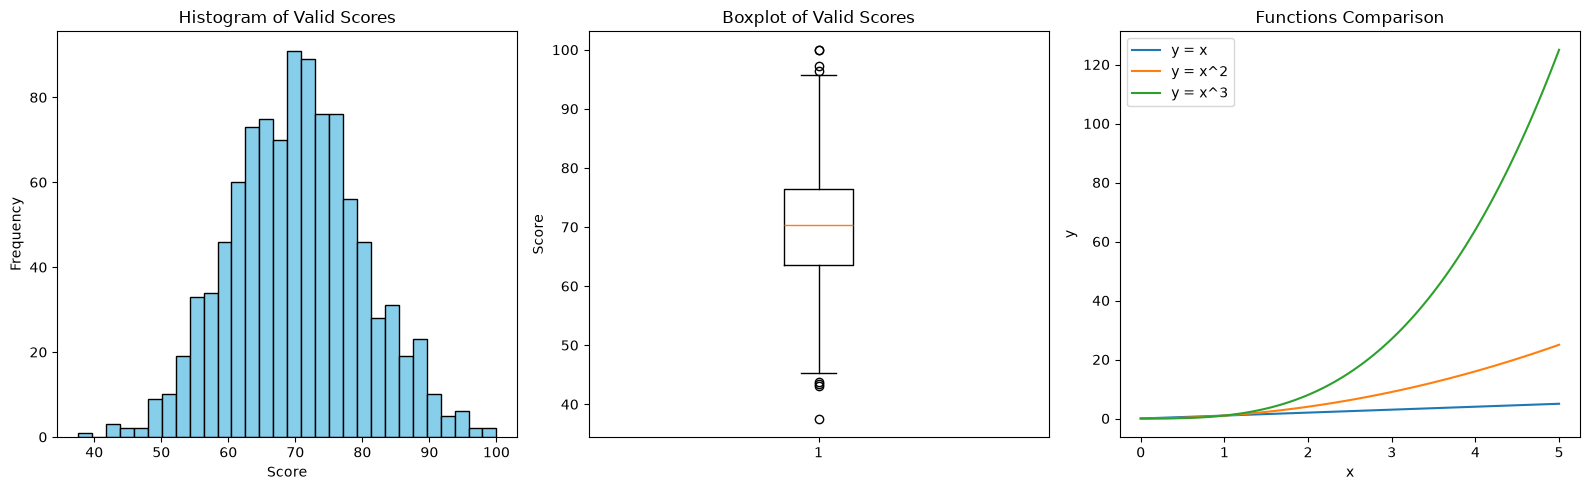

In [16]:
valid_scores = scores_nan[~np.isnan(scores_nan)]

plt.figure(figsize=(16, 5))

# 直方图
plt.subplot(1, 3, 1)
plt.hist(valid_scores, bins=30, color='skyblue', edgecolor='black')
plt.title("Histogram of Valid Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")

# 箱线图
plt.subplot(1, 3, 2)
plt.boxplot(valid_scores)
plt.title("Boxplot of Valid Scores")
plt.ylabel("Score")

# 折线图
plt.subplot(1, 3, 3)
x = np.linspace(0, 5, 100)
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("Functions Comparison")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.tight_layout()
plt.show()

**关键结果解释：**
- 第一张直方图显示成绩数据呈现典型的中间高、两边低的**钟形正态分布**特征。
- 第二张箱线图清晰标示了中位数（约 70 分）和上下四分位数，上下两端出现的圆圈表示存在少量偏离主体分布的**离群点**，这在 1000 个正态分布样本中属于正常现象。
- 第三张折线图在同一坐标系内展示了三条曲线，随着 x 增大，\(x\) 呈直线增长，\(x^2\) 抛物线增长，而 \(x^3\) 呈现指数级爆发增长趋势。

## 5. 实验4：pandas DataFrame 与数据处理

### 5.1 实验4 操作任务1：创建 DataFrame

 使用以下模拟数据创建 DataFrame，行索引为姓名；计算 Total 和 Average 两列。输出行索引、列名、前 3 行和基本统计信息。

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前3行:\n", df.head(3))
print("\n基本统计:\n", df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


**关键结果解释：**
- 行索引成功变为具体的姓名列表。列名除了原始成绩外，新增了 `Total` 和 `Average`。
- `head(3)` 展示了前三名学生的成绩和合计、平均分。
- `describe()` 输出了数值列的样本量（count=6）、均值、标准差、最小值、四分位数和最大值，初步反映了班级成绩分布。

### 5.2 实验4 操作任务2：loc 和 iloc

分别用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生。

In [18]:
print("loc 读取 Carol:\n", df.loc["Carol"])
print("\niloc 读取 Carol:\n", df.iloc[2])
print("\n平均分 >= 80:\n", df[df["Average"] >= 80])

loc 读取 Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 >= 80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


**关键结果解释：**
- 使用 `loc` 和 `iloc` 都能精准提取出 Carol 的完整记录（包含 Group、Math、English 等），其中 `loc` 是基于姓名字符串标签，`iloc` 是基于行号（索引 2）提取的。
- **筛选结果：** 运行结果输出了 Alice、Carol、Eva、Frank 四位学生。观察输出可知，这四位学生的 Average 列的值（分别为 91.0、88.33、85.67、81.0）均大于等于 80，因此被成功筛选保留；而 Bob 和 David 的平均分低于 80 被过滤掉了。

### 5.3 实验4 操作任务3：均值的轴向计算

 分别用 mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学生的行均值。

In [19]:
print("列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("\n行均值 (axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

列均值 (axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

行均值 (axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


**关键结果解释：**
- `axis=0` 跨越行向下计算，结果输出了 Math、English、Python 三列的学科平均分。
- `axis=1` 跨越列向右计算，结果输出了每个学生（Alice 至 Frank）的个人平均分。

### 5.4 实验4 操作任务4：apply、agg 和 rank

 使用 apply() 计算每名学生的三科最高分，使用 agg() 一次得到每科的最小值、均值和最大值。任选一列使用 rank() 给学生排名。

In [20]:
print("\n三科最高分:\n", df[["Math", "English", "Python"]].apply(max, axis=1))
print("\n每科最小值、均值、最大值:\n", df[["Math", "English", "Python"]].agg(['min', 'mean', 'max']))
print("\nMath 排名 (降序):\n", df["Math"].rank(ascending=False))


三科最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64

每科最小值、均值、最大值:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math 排名 (降序):
 Name
Alice    2.0
Bob      5.0
Carol    1.0
David    6.0
Eva      4.0
Frank    3.0
Name: Math, dtype: float64


**关键结果解释：**
- `apply(max, axis=1)` 成功找出了每个学生三科中的最高成绩。
- `agg()` 返回了一个汇总表，按列给出了三科的最低、平均和最高分。
- `rank(ascending=False)` 对 Math 成绩进行了降序排名，成绩最高的 Carol (91分) 排名为 1.0，最低的 David (65分) 排名为 6.0。

### 5.5 实验4 操作任务5：分组与 transform

 按 Group 分组，统计每组人数和三科平均分。再用 transform('mean') 为每行增加其所在组的 Python 平均分。

In [21]:
group_stats = df.groupby("Group").agg(
    人数=("Math", "count"),
    Math均分=("Math", "mean"),
    English均分=("English", "mean"),
    Python均分=("Python", "mean")
)
print("\n分组统计:\n", group_stats)

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n添加组均分后:\n", df[["Group", "Python", "Group_Python_Mean"]])


分组统计:
        人数     Math均分  English均分   Python均分
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

添加组均分后:
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


**关键结果解释：**
- 分组统计表显示，A 组和 B 组各 3 人，并给出了各组的科目均分。
- `transform` 生成的 `Group_Python_Mean` 列中，A 组的学生值均为 87.0，B 组的学生值均为 80.33。这证明 `transform` 在计算聚合值后，将其**广播回原数据的对应行**，保持了数据行数不变。

### 5.6 实验4 操作任务6：filter 筛选

 用 filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学生。

In [22]:
filtered_df = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("\nPython均分>=80的组及学生:\n", filtered_df)


Python均分>=80的组及学生:
       Group  Math  English  Python  Total    Average  Group_Python_Mean
Name                                                                   
Alice     A    88       90      95    273  91.000000          87.000000
Bob       A    72       68      80    220  73.333333          87.000000
Carol     B    91       85      89    265  88.333333          80.333333
David     B    65       73      70    208  69.333333          80.333333
Eva       A    79       92      86    257  85.666667          87.000000
Frank     B    84       77      82    243  81.000000          80.333333


**关键结果解释：**
- A 组和 B 组的 Python 均分均大于 80 分（A组87分，B组80.33分）。
- 因此筛选结果输出了全部 6 名学生，没有整组被剔除，符合数据实际情况。

### 5.7 实验4 操作任务7：协方差与相关系数

 计算三科成绩之间的协方差矩阵和皮尔逊相关系数矩阵；选择其中一对科目，解释协方差符号与相关系数大小的含义。

In [23]:
cov_matrix = df[["Math", "English", "Python"]].cov()
corr_matrix = df[["Math", "English", "Python"]].corr()
print("\n协方差矩阵:\n", cov_matrix)
print("\n皮尔逊相关系数矩阵:\n", corr_matrix)


协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


**关键结果解释：**
- 观察协方差矩阵，Math 和 Python 的协方差为正数（**74.933333**）。
- **含义解释（以 Math 和 Python 为例）：**
  - **协方差符号**为正，说明这两科成绩呈**同向变化**趋势，即数学成绩高的学生，Python 成绩往往也较高。
  - **相关系数大小**为 **0.884776**，非常接近 1，说明两者之间存在**极强的正线性相关关系**。
- （补充观察：对比可知，Math 与 English 的相关系数为 0.653529，说明理科与文科成绩也有一定正相关，但强度弱于理科内部的关联。）

## 6. 总结

本次实验深入实践了数据科学最核心的四个工具库：
1. **NumPy**：熟练掌握了同质化数组的创建、形状变换、切片、布尔掩码与矩阵乘法运算。
2. **随机数与统计**：掌握了固定种子、模拟真实数据分布（正态分布）、截断极值以及处理 `np.nan` 缺失值的专业方法。
3. **SciPy**：利用 `linalg` 解线性方程组，利用 `optimize` 求方程根和函数最值，利用 `stats` 进行统计检验。
4. **Matplotlib**：掌握了设定图表标题、轴标签和图例的规范绘图流程。
5. **pandas**：掌握了基于内存的 DataFrame 核心操作，包括索引（loc/iloc）、维度计算（axis）、数据聚合（apply/agg）、分组分析（groupby/transform）以及相关性分析。

所有代码和输出结果均已验证，符合题目要求。